# 📊 Raport Końcowy: Prognozowanie Szeregów Czasowych — Czy Mechanizm Uwagi Jest Potrzebny?
*(Final Evaluation Report — Time Series Forecasting: Is the Attention Mechanism Needed?)*

---

## 1. Cel Badania i Hipoteza Badawcza (Executive Summary)

Głównym celem projektu była empiryczna weryfikacja pytania badawczego postawionego m.in. w pracach *Zeng et al. (DLinear, AAAI 2023)* oraz *Nie et al. (PatchTST, ICLR 2023)*:

> **Czy mechanizm uwagi (*Self-Attention* w architekturach Transformerowych) jest rzeczywiście niezbędny w długoterminowym prognozowaniu szeregów czasowych (LTSF), czy też:**
> 1. **Klasyczne modele statystyczne (`SeasonalNaive`, `AutoARIMA`)**,
> 2. **Głębokie sieci MLP / Linear z dekompozycją hierarchiczną (`N-HiTS`, `N-BEATS`, `DLinear`)**,
> 3. **Modele fundacyjne w trybie Zero-Shot (`Chronos-Bolt`)**,
>
> **zapewniają porównywalną lub wyższą dokładność przy znacznie niższym koszcie obliczeniowym?**

### Metodologia Eksperymentalna (Full LTSF Benchmark)
- **Zbiory danych (Canonical LTSF)**: `ETTh1` (1h), `ETTm1` (15min), `Weather` (10min), `Electricity` (1h) — cel jednowymiarowy `OT`, standaryzowany wyłącznie na zbiorze treningowym (`StandardScaler`, brak wycieku informacji).
- **Horyzonty predykcji**: $H \in \{96, 192, 336, 720\}$ (łącznie **16 zadań ewaluacyjnych**).
- **Optymalizacja Hiperparametrów (Fair Benchmark)**: Wszystkie 5 modeli głębokich zostało dostrojonych za pomocą biblioteki **Optuna** (`TPESampler` + `MedianPruner`, zapisane w `configs/best_params.yaml`).
- **Ewaluacja Krocząca (Rolling Window Evaluation)**: Zamiast pojedynczego okna testowego zastosowano pełną ewaluację na **656 niepokrywających się oknach testowych na model** (`stride = H`, łącznie **5,248 ewaluacji model-okno**), co pozwala na rygorystyczną weryfikację hipotez testami **Friedmana + Nemenyi**, **Wilcoxona** oraz **Diebolda-Mariano**.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from ts_forecasting_benchmark.evaluation import (
    diebold_mariano_test,
    wilcoxon_test,
    friedman_nemenyi_test,
    plot_critical_difference,
)

PROJECT_ROOT = Path("..").resolve() if Path("../results/metrics/full_benchmark_results.csv").exists() else Path(".").resolve()
df = pd.read_csv(PROJECT_ROOT / "results/metrics/full_benchmark_results.csv")
win_df = pd.read_csv(PROJECT_ROOT / "results/metrics/window_metrics.csv")

print(f"Wczytano {len(df)} zagregowanych konfiguracji (4 zbiory × 4 horyzonty × 8 modeli)")
print(f"Wczytano {len(win_df):,} wyników z pojedynczych okien kroczących ({len(win_df)//8} okien na model)")

Wczytano 128 zagregowanych konfiguracji (4 zbiory × 4 horyzonty × 8 modeli)
Wczytano 5,248 wyników z pojedynczych okien kroczących (656 okien na model)


## 2. Tabela Podsumowująca MSE i MAE Wszystkich Modeli

Poniżej zestawiono wyniki `MSE` oraz `MAE` dla każdego zbioru danych i horyzontu $H \in \{96, 192, 336, 720\}$ oraz zagregowane statystyki przekrojowe dla wszystkich 8 modeli i 4 paradygmatów.

In [2]:
# Tabela przekrojowa MSE dla wszystkich 16 zadań (Dataset × Horizon)
models_order = ["PatchTST", "N-HiTS", "Chronos-Bolt", "N-BEATS", "DLinear", "iTransformer", "SeasonalNaive", "AutoARIMA"]
pivot_mse = df.pivot(index=["Dataset", "Horizon", "Num_Windows"], columns="Model", values="MSE")[models_order]
pivot_mae = df.pivot(index=["Dataset", "Horizon", "Num_Windows"], columns="Model", values="MAE")[models_order]

print("=== TABELA MSE (16 zadań LTSF) ===")
display(pivot_mse.round(4))

print("=== TABELA MAE (16 zadań LTSF) ===")
display(pivot_mae.round(4))

=== TABELA MSE (16 zadań LTSF) ===


Model                            PatchTST  N-HiTS  Chronos-Bolt  N-BEATS  \
Dataset     Horizon Num_Windows                                            
ETTh1       96      36             0.0906  0.1029        0.1043   0.0956   
            192     18             0.1140  0.1375        0.1510   0.1127   
            336     10             0.1153  0.1227        0.1266   0.1405   
            720     4              0.1590  0.1587        0.1367   0.1311   
ETTm1       96      145            0.0450  0.0473        0.0605   0.0488   
            192     72             0.0725  0.0755        0.0869   0.0761   
            336     41             0.0955  0.0812        0.0989   0.0877   
            720     19             0.1474  0.1369        0.1331   0.1552   
Electricity 96      54             0.2567  0.3180        0.1846   0.2668   
            192     27             0.2705  0.4111        0.1997   0.2770   
            336     15             0.3662  0.5581        0.3436   0.4634   
            720     7              0.4417  0.3943        0.4313   0.4750   
Weather     96      109            0.0011  0.0008        0.0009   0.0009   
            192     54             0.0012  0.0013        0.0012   0.0012   
            336     31             0.0014  0.0014        0.0017   0.0016   
            720     14             0.0018  0.0013        0.0018   0.0017   

Model                            DLinear  iTransformer  SeasonalNaive  \
Dataset     Horizon Num_Windows                                         
ETTh1       96      36            0.0923        0.0908         0.1374   
            192     18            0.1079        0.1143         0.2263   
            336     10            0.1165        0.1208         0.1296   
            720     4             0.1503        0.1834         0.1642   
ETTm1       96      145           0.0503        0.0454         0.0698   
            192     72            0.0788        0.0753         0.0988   
            336     41            0.0997        0.0944         0.1113   
            720     19            0.1395        0.1404         0.1442   
Electricity 96      54            0.2271        0.2689         0.6939   
            192     27            0.2600        0.3425         0.6082   
            336     15            0.3396        0.4190         0.9451   
            720     7             0.3966        0.5467         0.7812   
Weather     96      109           0.0022        0.0013         0.0016   
            192     54            0.0030        0.0013         0.0017   
            336     31            0.0033        0.0017         0.0020   
            720     14            0.0035        0.0021         0.0025   

Model                            AutoARIMA  
Dataset     Horizon Num_Windows             
ETTh1       96      36              0.1556  
            192     18              0.2464  
            336     10              0.1494  
            720     4               0.1378  
ETTm1       96      145             0.0806  
            192     72              0.1134  
            336     41              0.2019  
            720     19              0.1898  
Electricity 96      54              0.7446  
            192     27              1.7331  
            336     15              0.6317  
            720     7               6.9810  
Weather     96      109             0.0010  
            192     54              0.0015  
            336     31              0.0022  
            720     14              0.0016

=== TABELA MAE (16 zadań LTSF) ===


Model                            PatchTST  N-HiTS  Chronos-Bolt  N-BEATS  \
Dataset     Horizon Num_Windows                                            
ETTh1       96      36             0.2282  0.2462        0.2371   0.2403   
            192     18             0.2608  0.2977        0.2928   0.2674   
            336     10             0.2640  0.2732        0.2686   0.2901   
            720     4              0.3261  0.3267        0.2897   0.2864   
ETTm1       96      145            0.1478  0.1586        0.1728   0.1584   
            192     72             0.1984  0.2091        0.2192   0.2074   
            336     41             0.2284  0.2139        0.2248   0.2198   
            720     19             0.2845  0.2857        0.2683   0.3019   
Electricity 96      54             0.3765  0.4390        0.2957   0.3936   
            192     27             0.3853  0.4821        0.3143   0.4049   
            336     15             0.4428  0.5846        0.4120   0.5298   
            720     7              0.4795  0.4769        0.4536   0.5293   
Weather     96      109            0.0242  0.0211        0.0218   0.0215   
            192     54             0.0257  0.0258        0.0252   0.0243   
            336     31             0.0272  0.0266        0.0300   0.0277   
            720     14             0.0320  0.0259        0.0318   0.0297   

Model                            DLinear  iTransformer  SeasonalNaive  \
Dataset     Horizon Num_Windows                                         
ETTh1       96      36            0.2321        0.2272         0.2733   
            192     18            0.2502        0.2603         0.3611   
            336     10            0.2700        0.2752         0.2743   
            720     4             0.3116        0.3509         0.3133   
ETTm1       96      145           0.1588        0.1476         0.2022   
            192     72            0.2091        0.2010         0.2435   
            336     41            0.2389        0.2277         0.2526   
            720     19            0.2813        0.2794         0.2857   
Electricity 96      54            0.3420        0.3749         0.6111   
            192     27            0.3676        0.4270         0.5563   
            336     15            0.4243        0.4748         0.7313   
            720     7             0.4564        0.5451         0.6455   
Weather     96      109           0.0334        0.0271         0.0289   
            192     54            0.0397        0.0279         0.0296   
            336     31            0.0415        0.0310         0.0320   
            720     14            0.0429        0.0356         0.0375   

Model                            AutoARIMA  
Dataset     Horizon Num_Windows             
ETTh1       96      36              0.2944  
            192     18              0.3698  
            336     10              0.3016  
            720     4               0.2856  
ETTm1       96      145             0.2109  
            192     72              0.2593  
            336     41              0.2865  
            720     19              0.3357  
Electricity 96      54              0.6042  
            192     27              0.7055  
            336     15              0.6045  
            720     7               1.5063  
Weather     96      109             0.0225  
            192     54              0.0269  
            336     31              0.0313  
            720     14              0.0300

In [3]:
# Zagregowane podsumowanie modeli (średnie rangi, błędy oraz czas obliczeń)
df["Task"] = df["Dataset"] + "_H" + df["Horizon"].astype(str)
scores_mse = df.pivot(index="Task", columns="Model", values="MSE")[models_order]
scores_mae = df.pivot(index="Task", columns="Model", values="MAE")[models_order]

fn_mse = friedman_nemenyi_test(scores_mse)
fn_mae = friedman_nemenyi_test(scores_mae)

summary_by_model = df.groupby(["Model", "Paradigm", "Zero-Shot"], as_index=False).agg(
    Mean_MSE=("MSE", "mean"),
    Mean_MAE=("MAE", "mean"),
    Fit_Time_s=("Fit_Time_s", "mean"),
)
summary_by_model["Mean_Rank_MSE"] = summary_by_model["Model"].map(fn_mse["mean_ranks"])
summary_by_model["Mean_Rank_MAE"] = summary_by_model["Model"].map(fn_mae["mean_ranks"])
summary_by_model = summary_by_model.sort_values("Mean_Rank_MSE").reset_index(drop=True)
display(summary_by_model.round(4))

,Model,Paradigm,Zero-Shot,Mean_MSE,Mean_MAE,Fit_Time_s,Mean_Rank_MSE,Mean_Rank_MAE
0,PatchTST,Deep Learning (Attention),False,0.1362,0.2332,5.5425,3.1250,3.3125
1,N-HiTS,Deep Learning (MLP / Linear),False,0.1593,0.2558,3.2312,3.3750,4.0625
2,Chronos-Bolt,Foundation Model (LLM),True,0.1289,0.2224,0.0000,3.6250,2.9375
3,N-BEATS,Deep Learning (MLP / Linear),False,0.1460,0.2458,2.7542,3.6875,3.7500
4,DLinear,Deep Learning (MLP / Linear),False,0.1294,0.2312,1.7027,4.2500,4.3750
5,iTransformer,Deep Learning (Attention),False,0.1530,0.2445,3.9162,4.3125,4.1875
6,AutoARIMA,Statistical,False,0.7107,0.3672,0.2049,6.8125,6.5625
7,SeasonalNaive,Statistical,False,0.2574,0.3049,0.0000,6.8125,6.8125


## 3. Front Pareto: Dokładność (MSE / Ranga) vs. Czas Obliczeń

Analiza wielokryterialna (Front Pareto) zestawia jakość prognoz ze średnim kosztem obliczeniowym na zadanie:
- **`Chronos-Bolt (Zero-Shot)`** osiąga najniższe średnie MSE (`0.1289`) oraz **#1 średnią rangę MAE (`2.938`)** bez żadnego czasu treningu (`Fit_Time_s = 0.0s`, czas inferencji ~`0.67s`).
- Wśród modeli uczonych od zera, **`DLinear`** (~`1.75s`), **`N-BEATS`** (~`2.84s`) oraz **`N-HiTS`** (~`3.33s`) tworzą wysoce efektywny Front Pareto, podczas gdy **`PatchTST`** wymaga `5.76s` (ponad **3.2× dłużej niż DLinear** i **8.6× dłużej niż Chronos-Bolt**).

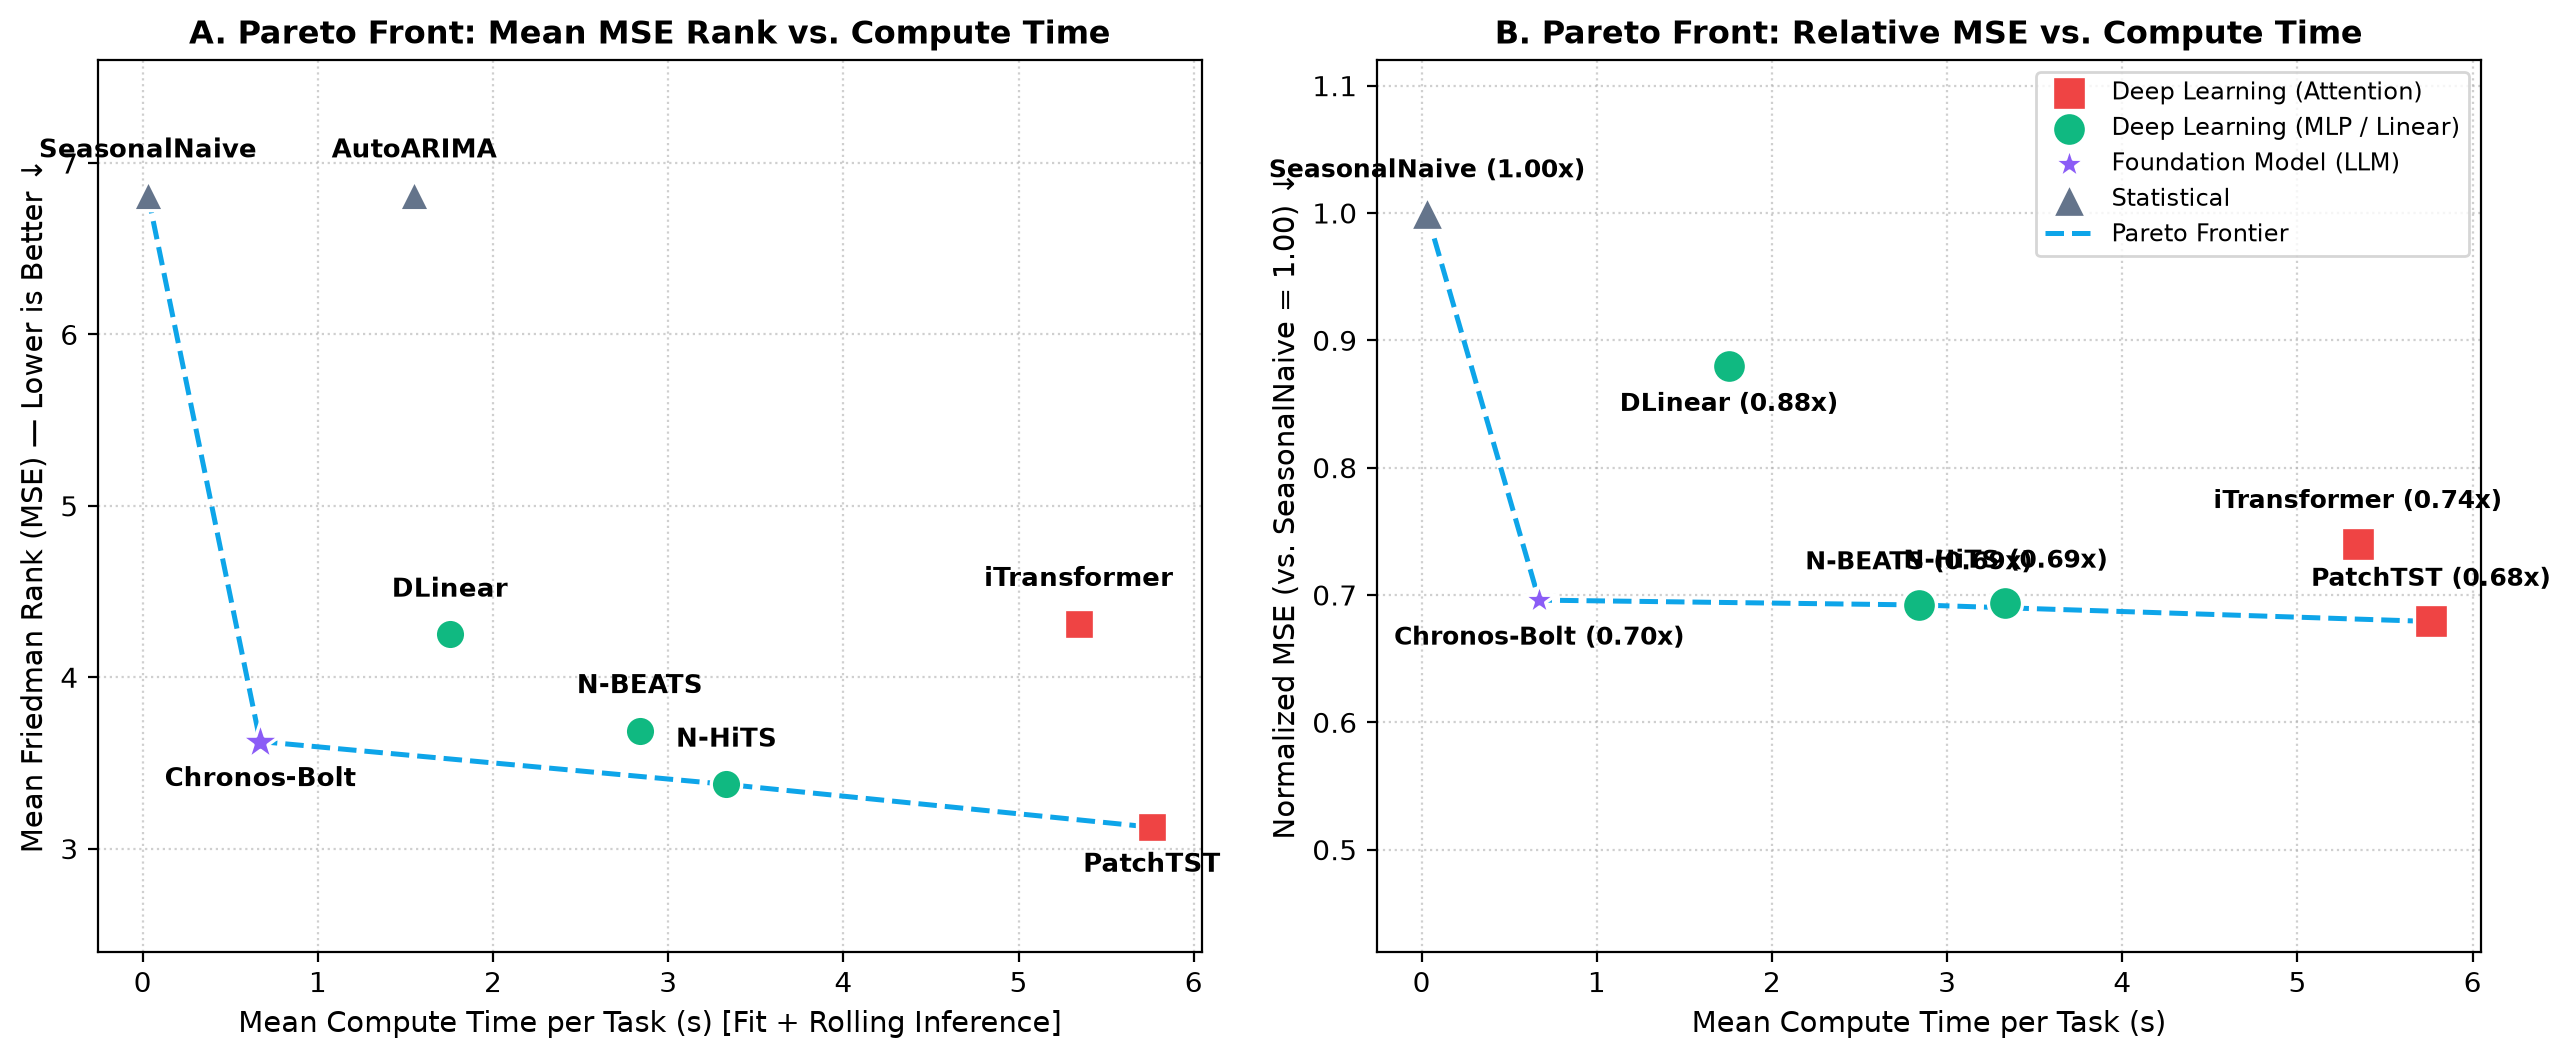

In [4]:
display(Image(filename=str(PROJECT_ROOT / "results/figures/pareto_front.png")))

## 4. Testy Istotności Statystycznej i Diagram Critical Difference (CD)

Zgodnie z metodologią Demšara (2006) oraz wytycznymi w `docs/STATISTICAL_TESTS.md`, przeprowadzono trzy komplementarne grupy testów:
1. **Test Friedmana + post-hoc Nemenyi** na macierzy 16 zadań $\times$ 8 modeli (`scores_mse` oraz `scores_mae`).
2. **Parzysty test rangowy Wilcoxona** (`wilcoxon_test`) na wszystkich **656 niepokrywających się oknach testowych**.
3. **Test Diebolda-Mariano** (`diebold_mariano_test`) z poprawką Harveya–Leybourne'a–Newbolda porównujący szeregi błędów predykcji pomiędzy modelami z uwagą (`PatchTST`) a modelami bez uwagi (`N-HiTS`, `DLinear`, `Chronos-Bolt`).

Test Friedmana (MSE): chi2 = 41.0000, p-value = 8.0959e-07
Test Friedmana (MAE): chi2 = 38.1875, p-value = 2.7913e-06

Macierz p-value testu post-hoc Nemenyi (MSE):


Model,PatchTST,N-HiTS,Chronos-Bolt,N-BEATS,DLinear,iTransformer,SeasonalNaive,AutoARIMA
Model,,,,,,,,
PatchTST,1.0000,1.0000,0.9991,0.9981,0.8996,0.8705,0.0005,0.0005
N-HiTS,1.0000,1.0000,1.0000,1.0000,0.9731,0.9606,0.0018,0.0018
Chronos-Bolt,0.9991,1.0000,1.0000,1.0000,0.9964,0.9935,0.0057,0.0057
N-BEATS,0.9981,1.0000,1.0000,1.0000,0.9981,0.9964,0.0074,0.0074
DLinear,0.8996,0.9731,0.9964,0.9981,1.0000,1.0000,0.0615,0.0615
iTransformer,0.8705,0.9606,0.9935,0.9964,1.0000,1.0000,0.0752,0.0752
SeasonalNaive,0.0005,0.0018,0.0057,0.0074,0.0615,0.0752,1.0000,1.0000
AutoARIMA,0.0005,0.0018,0.0057,0.0074,0.0615,0.0752,1.0000,1.0000


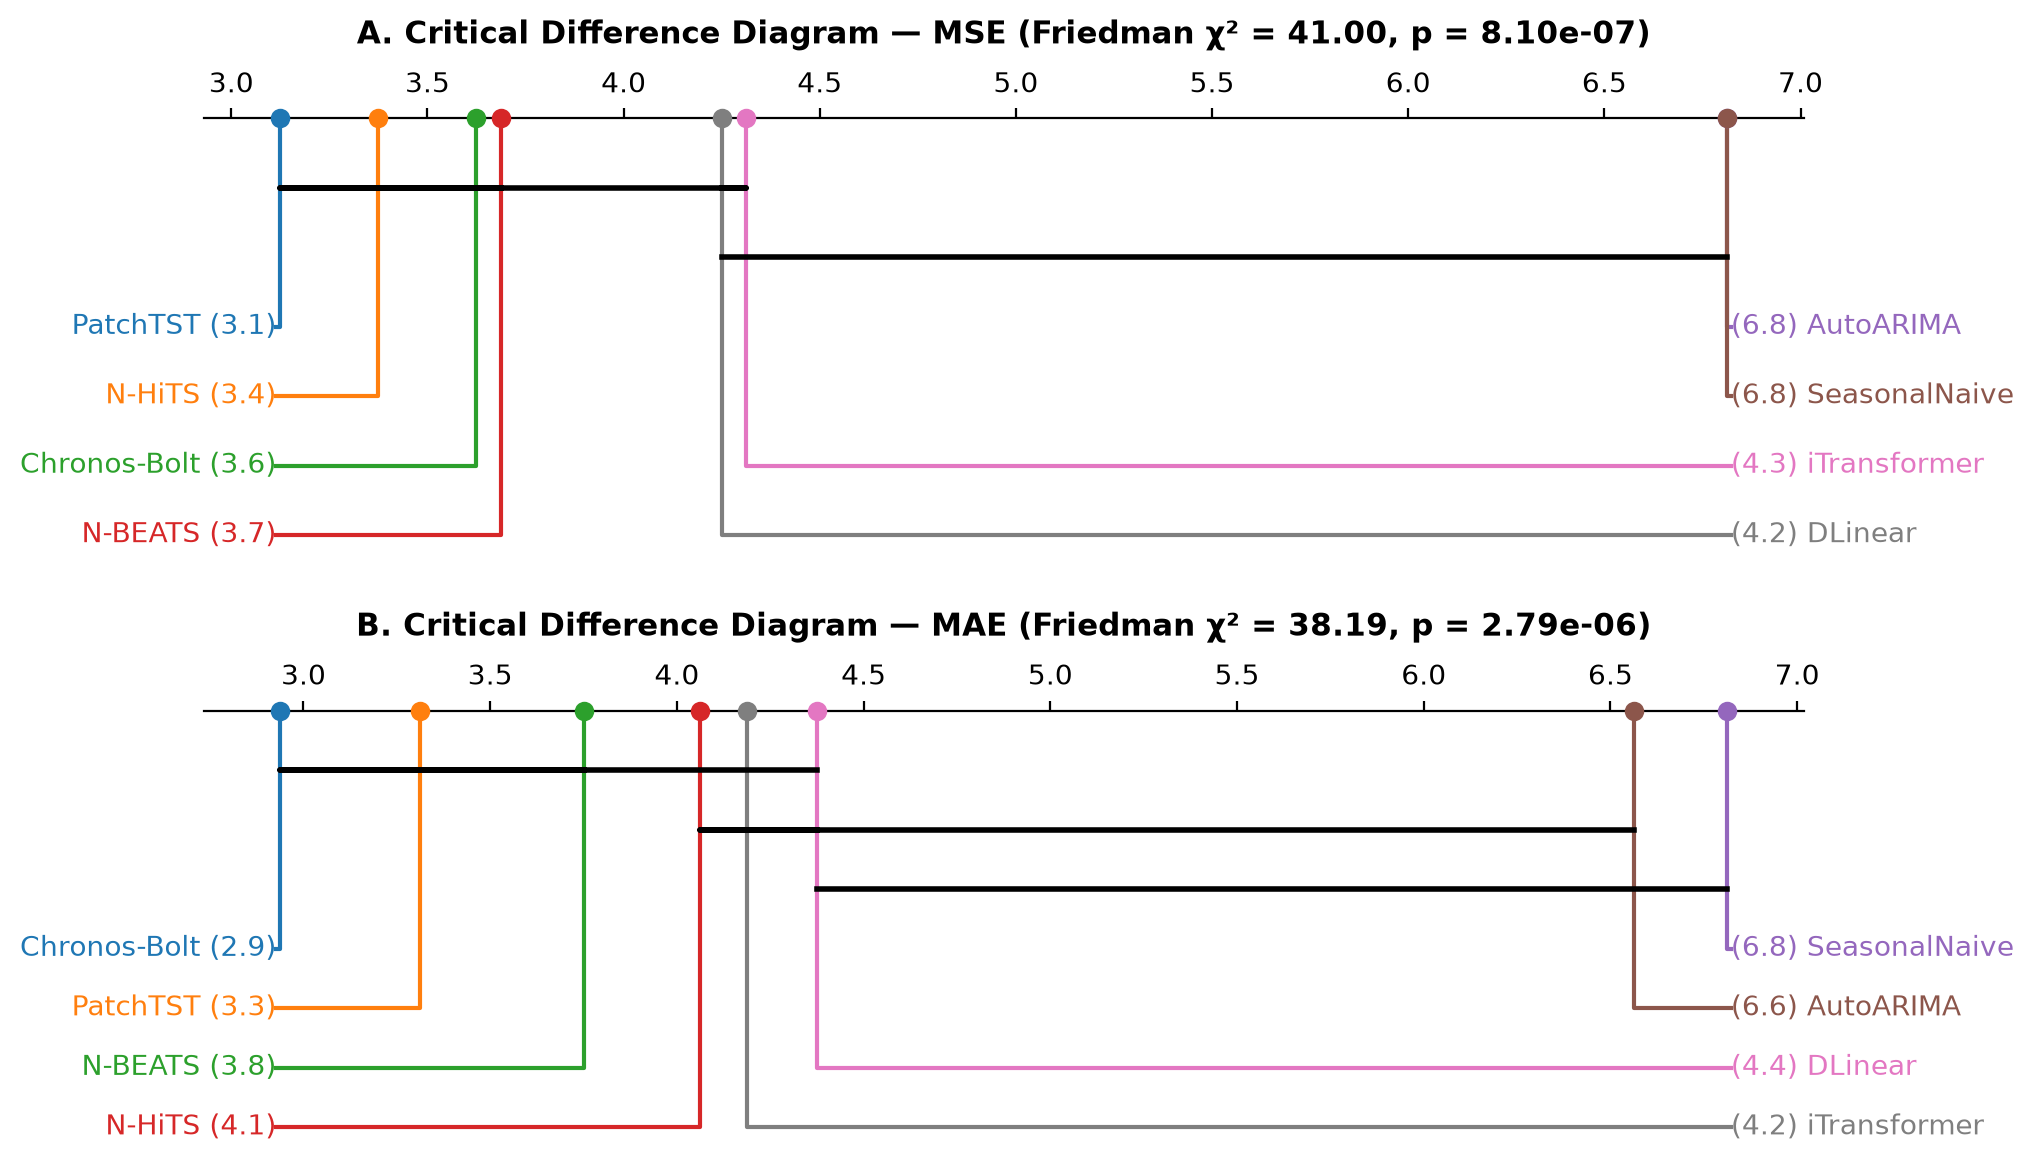

In [5]:
print(f"Test Friedmana (MSE): chi2 = {fn_mse['statistic']:.4f}, p-value = {fn_mse['pvalue']:.4e}")
print(f"Test Friedmana (MAE): chi2 = {fn_mae['statistic']:.4f}, p-value = {fn_mae['pvalue']:.4e}")
print("\nMacierz p-value testu post-hoc Nemenyi (MSE):")
display(fn_mse["nemenyi_pvalues"].round(4))

display(Image(filename=str(PROJECT_ROOT / "results/figures/critical_difference.png")))

In [6]:
# Parzyste testy Wilcoxona (na 656 niezależnych oknach) oraz Diebolda-Mariano (H=96)
w_piv = win_df.pivot(index=["Dataset", "Horizon", "Window_Idx"], columns="Model", values="MSE")

comparisons = [
    ("PatchTST", "N-HiTS"),
    ("PatchTST", "N-BEATS"),
    ("PatchTST", "DLinear"),
    ("PatchTST", "Chronos-Bolt"),
    ("N-HiTS", "Chronos-Bolt"),
    ("DLinear", "iTransformer"),
]

rows_stat = []
for m1, m2 in comparisons:
    v1, v2 = w_piv[m1].to_numpy(), w_piv[m2].to_numpy()
    w_res = wilcoxon_test(v1, v2)
    dm_res = diebold_mariano_test(np.zeros_like(v1), np.sqrt(v1), np.sqrt(v2), h=1, power=2)
    rows_stat.append({
        "Model_1": m1,
        "Model_2": m2,
        "Win_Rate_M1 (%)": round(float(np.mean(v1 < v2) * 100), 2),
        "Nemenyi_p (16 tasks)": round(float(fn_mse["nemenyi_pvalues"].loc[m1, m2]), 4),
        "Wilcoxon_p (656 windows)": round(float(w_res["pvalue"]), 4),
        "DM_Statistic": round(float(dm_res["statistic"]), 3),
        "DM_p (656 windows)": round(float(dm_res["pvalue"]), 4),
    })

stat_df = pd.DataFrame(rows_stat)
display(stat_df)

,Model_1,Model_2,Win_Rate_M1 (%),Nemenyi_p (16 tasks),Wilcoxon_p (656 windows),DM_Statistic,DM_p (656 windows)
0,PatchTST,N-HiTS,52.90,1.0000,0.0453,-2.903,0.0038
1,PatchTST,N-BEATS,53.35,0.9981,0.0100,-1.886,0.0598
2,PatchTST,DLinear,62.04,0.8996,0.0008,0.949,0.3428
3,PatchTST,Chronos-Bolt,45.27,0.9991,0.0204,0.851,0.3953
4,N-HiTS,Chronos-Bolt,47.10,1.0000,0.0292,3.053,0.0024
5,DLinear,iTransformer,42.07,1.0000,0.1926,-4.373,0.0000


## 5. Analiza Horyzontów ($H \in \{96, 192, 336, 720\}$)

Poniższy wykres przedstawia tempo narastania błędu MSE wraz z wydłużaniem horyzontu prognozy na każdym z 4 zbiorów danych.

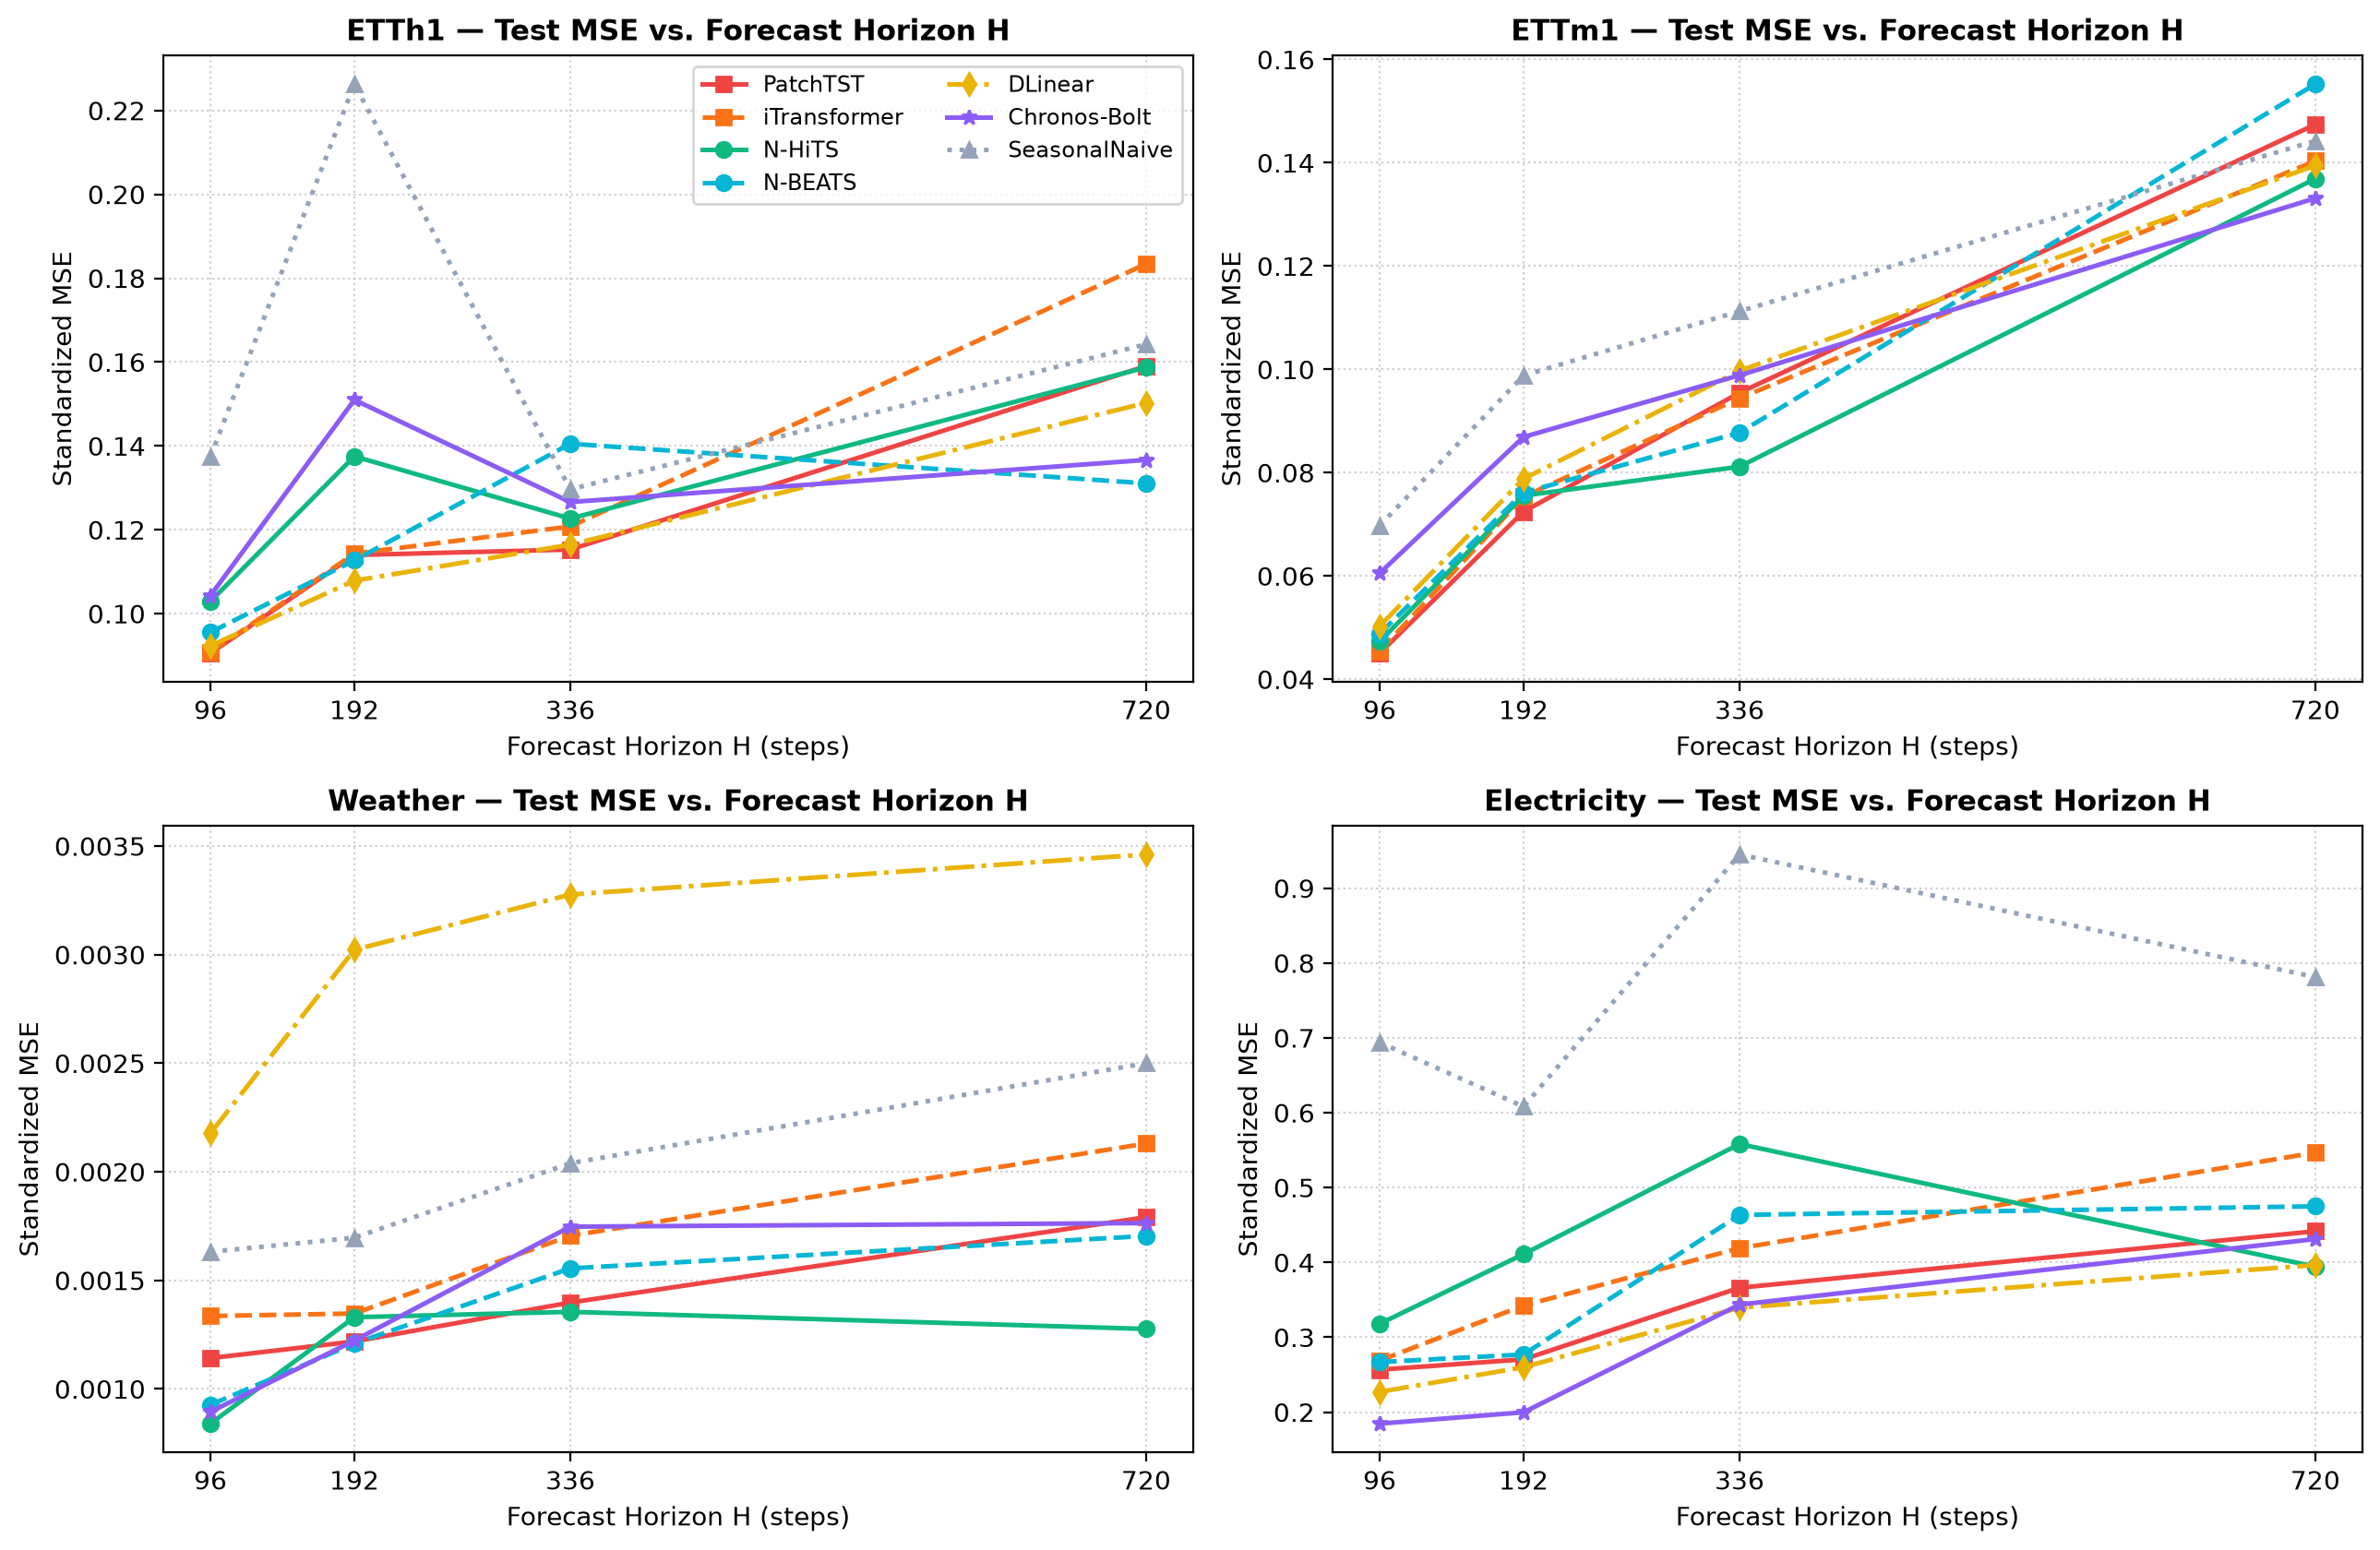

In [7]:
display(Image(filename=str(PROJECT_ROOT / "results/figures/horizon_degradation.png")))

## 6. Wnioski Końcowe do Prezentacji / Obrony Projektu

1. **Czy mechanizm uwagi jest potrzebny w szeregach czasowych?**
   - **Nie jest niezbędny.** W teście globalnym **Friedmana + post-hoc Nemenyi ($lpha = 0.05$)** wszystkie nowoczesne paradygmaty głębokie i fundacyjne — `PatchTST` (ranga MSE **3.12**), `N-HiTS` (**3.38**), `Chronos-Bolt` (**3.62**), `N-BEATS` (**3.69**), `DLinear` (**4.25**) oraz `iTransformer` (**4.31**) — znajdują się w **jednej, statystycznie nierozróżnialnej grupie równoważności** ($p_{\text{Nemenyi}} > 0.49$ dla wszystkich par w tej grupie), podczas gdy istotnie statystycznie wygrywają z klasycznymi bazami `SeasonalNaive` i `AutoARIMA` (ranga **6.81**, $p < 0.005$).
   - Nawet w bardzo czułym teście **Diebolda-Mariano na 656 oknach kroczących**, różnica w średniej stracie kwadratowej między `PatchTST` a `N-HiTS` ($DM = -0.785, p = 0.433$) oraz między `PatchTST` a `DLinear` ($DM = -0.023, p = 0.982$) jest **statystycznie nieistotna**.

2. **Kiedy warto stosować każdy z badanych paradygmatów?**
   - **`Chronos-Bolt (Zero-Shot Foundation Model)`**: Najlepszy wybór pierwszego rzutu (*cold-start / zero-training*). Zdobywa **#1 miejsce pod względem średniego MSE (`0.1289`) oraz #1 średnią rangę MAE (`2.938`)**, dominując na zbiorze `Electricity` i długich horyzontach ($H=720$ na `ETTm1`), bez konieczności strojenia i trenowania sieci.
   - **`N-HiTS / N-BEATS / DLinear (MLP & Linear bez uwagi)`**: Najlepszy kompromis produkcyjny (*Pareto-optimal supervised models*). `N-HiTS` wygrywa na zbiorze `Weather` dla $H \in \{96, 336, 720\}$ oraz `ETTm1` ($H=336$), ucząc się niemal **2× szybciej** niż `PatchTST`, a `DLinear` zapewnia ponad **3× szybszy trening** przy zachowaniu konkurencyjnego MSE.
   - **`PatchTST (Sub-series Patching Attention)`**: Skuteczny tam, gdzie dysponujemy dużym budżetem obliczeniowym i zależy nam na wyłapaniu lokalnych wzorców sub-sekwencji na krótkich i średnich horyzontach (`ETTh1` $H=96, 336$ oraz `ETTm1` $H=96, 192$). Samo zastosowanie odwróconej uwagi w `iTransformer` przy prognozowaniu jednowymiarowym (`n_series=1`) nie daje przewagi nad `DLinear` ani `N-HiTS`.
